# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [19]:
# Replace None with your code
# Imports
import pandas as pd
import sqlite3


# Create connection to database
conn=sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [20]:
# Replace None with your code
df=pd.read_sql("""SELECT * FROM customers;""",conn).head()
df

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,103,Atelier graphique,Schmitt,Carine,40.32.2555,"54, rue Royale",,Nantes,,44000,France,1370,21000.00
1,112,Signal Gift Stores,King,Jean,7025551838,8489 Strong St.,,Las Vegas,NV,83030,USA,1166,71800.00
2,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
3,119,La Rochelle Gifts,Labrune,Janine,40.67.8555,"67, rue des Cinquante Otages",,Nantes,,44000,France,1370,118200.00
4,121,Baane Mini Imports,Bergulfsen,Jonas,07-98 9555,Erling Skakkes gate 78,,Stavern,,4110,Norway,1504,81700.00


In [21]:
query="""SELECT  contactFirstName,
    contactLastName,
    phone,
    addressLine1,
    creditLimit FROM customers WHERE state = "CA" AND CAST(creditLimit AS INTEGER) >25000;"""
promotion_cust=pd.read_sql(query,conn)
promotion_cust

,contactFirstName,contactLastName,phone,addressLine1,creditLimit
0,Susan,Nelson,4155551450,5677 Strong St.,210500.00
1,Julie,Murphy,6505555787,5557 North Pendale Street,64600.00
2,Juri,Hashimoto,6505556809,9408 Furth Circle,84600.00
3,Julie,Young,6265557265,78934 Hillside Dr.,90700.00
4,Valarie,Thompson,7605558146,361 Furth Circle,105000.00
5,Julie,Brown,6505551386,7734 Strong St.,105000.00
6,Brian,Chandler,2155554369,6047 Douglas Av.,57700.00
7,Sue,Frick,4085553659,3086 Ingle Ln.,77600.00
8,Steve,Thompson,3105553722,3675 Furth Circle,55400.00
9,Sue,Taylor,4155554312,2793 Furth Circle,60300.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [22]:
# Replace None with your code
query2="""SELECT * FROM customers WHERE country!="USA" AND customerName LIKE "%Collect%";"""
pd.read_sql(query2,conn)

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!
The WHERE clause filters the customers to include only those who are located outside the United States and whose customer name contains the word "Collect". 
The `!=` operator excludes customers whose country is recorded as USA
The `LIKE` operator with `%Collect%` searches for the word anywhere within the customer name. 
The `AND` operator ensures that both conditions must be satisfied before a customer is included in the results.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [23]:
query = """
SELECT
    state,
    AVG(creditLimit) AS average_credit_limit,
    COUNT(customerNumber) AS number_of_customers
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY average_credit_limit DESC;
"""

state_credit = pd.read_sql(query, conn)
state_credit

,state,average_credit_limit,number_of_customers
0,NH,114200.000000,1
1,NY,89966.666667,6
2,PA,84766.666667,3
3,CA,83854.545455,11
4,NV,71800.000000,1
5,MA,70755.555556,9
6,CT,57350.000000,4
7,NJ,43000.000000,1


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

In [24]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
import matplotlib.pyplot as plt
import seaborn as sns 

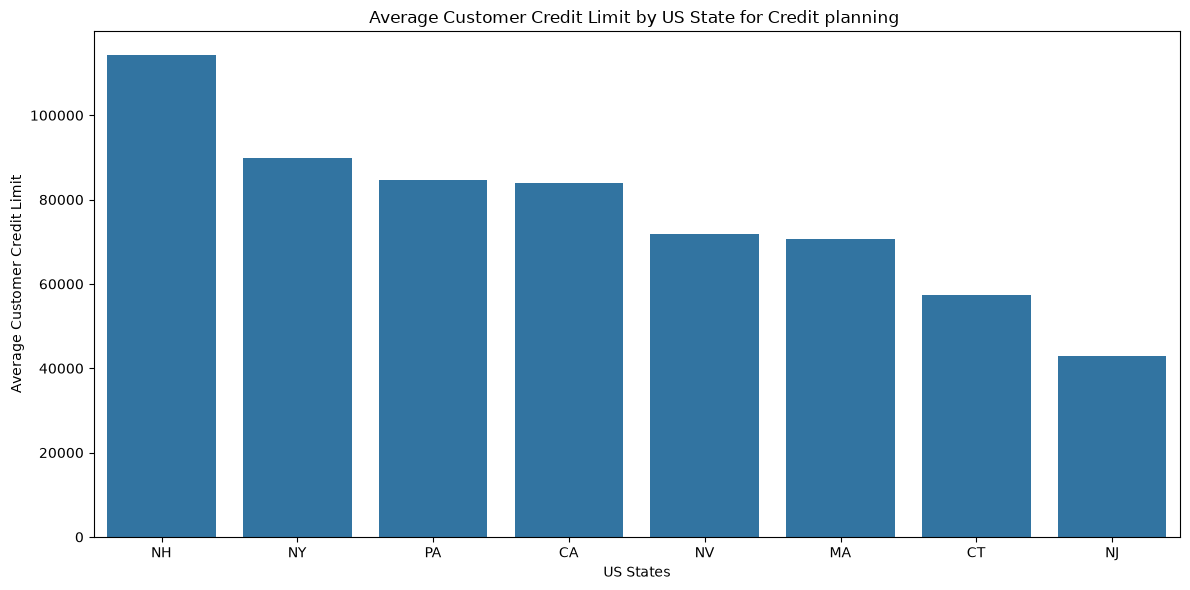

In [25]:
plt.figure(figsize=(12,6))
sns.barplot(data=state_credit, x="state", y="average_credit_limit")
plt.title("Average Customer Credit Limit by US State for Credit planning ")
plt.xlabel("US States")
plt.ylabel("Average Customer Credit Limit")
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [26]:
# Replace None with your code
query = """SELECT customers.customerName,SUM(payments.amount) AS total_payments FROM customers JOIN payments
ON customers.customerNumber = payments.customerNumber GROUP BY customers.customerNumber, customers.customerName
ORDER BY total_payments DESC LIMIT 10; """

top_10_customers = pd.read_sql(query, conn)
top_10_customers

,customerName,total_payments
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

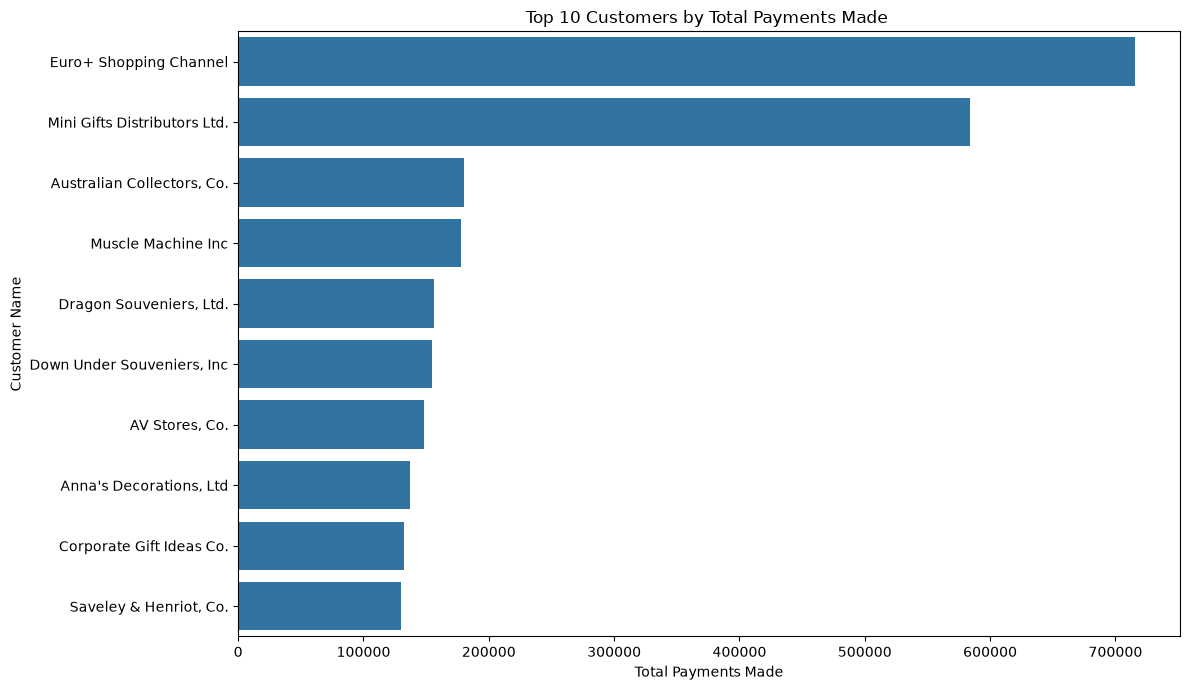

In [27]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(data=top_10_customers,x="total_payments",y="customerName")

plt.title("Top 10 Customers by Total Payments Made ")
plt.xlabel("Total Payments Made")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [28]:
# Replace None with you code
query = """
SELECT
    customers.customerName,
    products.productName,
    SUM(orderdetails.quantityOrdered) AS total_quantity_purchased
FROM customers
JOIN orders
    ON customers.customerNumber = orders.customerNumber
JOIN orderdetails
    ON orders.orderNumber = orderdetails.orderNumber
JOIN products
    ON orderdetails.productCode = products.productCode
GROUP BY
    customers.customerNumber,
    customers.customerName,
    products.productCode,
    products.productName
HAVING SUM(orderdetails.quantityOrdered) >= 10
ORDER BY total_quantity_purchased ASC;
"""

customer_products = pd.read_sql(query, conn)
customer_products

,customerName,productName,total_quantity_purchased
0,Petit Auto,1913 Ford Model T Speedster,10
1,"Extreme Desk Decorations, Ltd",1961 Chevrolet Impala,10
2,La Rochelle Gifts,1954 Greyhound Scenicruiser,11
3,Tekni Collectables Inc.,American Airlines: B767-300,11
4,The Sharp Gifts Warehouse,1969 Chevrolet Camaro Z28,13
...,...,...,...
2526,Euro+ Shopping Channel,2002 Chevy Corvette,174
2527,Euro+ Shopping Channel,1957 Chevy Pickup,183
2528,Euro+ Shopping Channel,1970 Dodge Coronet,197
2529,Euro+ Shopping Channel,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [29]:
# Replace None with your code
query = """
SELECT products.productLine, COUNT(DISTINCT products.productCode) AS number_of_products, SUM(orderdetails.quantityOrdered) AS total_quantity_ordered
FROM products JOIN orderdetails ON products.productCode = orderdetails.productCode GROUP BY products.productLine;"""

product_line_data = pd.read_sql(query, conn)
product_line_data

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Motorcycles,13,12778
2,Planes,12,11872
3,Ships,9,8532
4,Trains,3,2818
5,Trucks and Buses,11,11001
6,Vintage Cars,24,22933


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

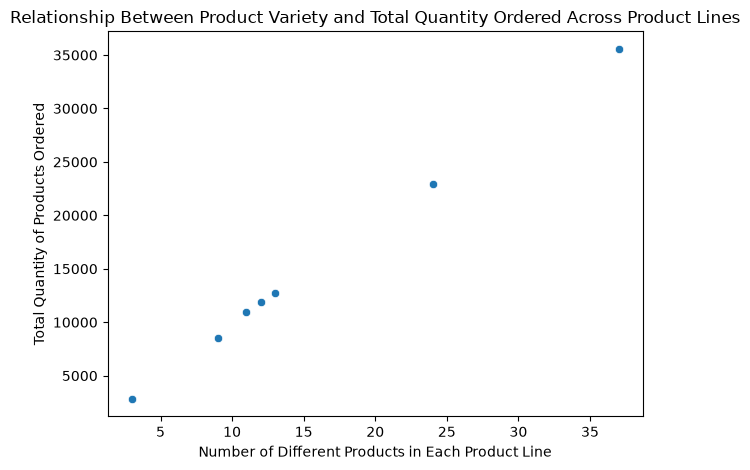

In [30]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered

import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=product_line_data, x="number_of_products", y="total_quantity_ordered")

plt.title("Relationship Between Product Variety and Total Quantity Ordered Across Product Lines")
plt.xlabel("Number of Different Products in Each Product Line")
plt.ylabel("Total Quantity of Products Ordered")

plt.tight_layout()
plt.show()


## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [31]:
# Replace None with your code
query = """
SELECT employees.firstName,employees.lastName,employees.jobTitle,employees.officeCode,employees.reportsTo
FROM employees
WHERE employees.officeCode IN (SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(*) < 5);"""

small_office_employees = pd.read_sql(query, conn)
small_office_employees

,firstName,lastName,jobTitle,officeCode,reportsTo
0,William,Patterson,Sales Manager (APAC),6,1056
1,Julie,Firrelli,Sales Rep,2,1143
2,Steve,Patterson,Sales Rep,2,1143
3,Foon Yue,Tseng,Sales Rep,3,1143
4,George,Vanauf,Sales Rep,3,1143
5,Larry,Bott,Sales Rep,7,1102
6,Barry,Jones,Sales Rep,7,1102
7,Andy,Fixter,Sales Rep,6,1088
8,Peter,Marsh,Sales Rep,6,1088
9,Tom,King,Sales Rep,6,1088


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!
I used a subquery to identify offices with fewer than five employees. The subquery groups employees by officeCode and uses COUNT(*) to calculate the number of employees in each office. The HAVING clause filters the groups to include only offices with fewer than five employees. The main query then uses the IN operator to select employees whose officeCode matches one of the offices returned by the subquery. This ensures that the results include only employees working in small offices, along with their job titles and supervisor employee numbers.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [32]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [33]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [34]:
# Begin your code here

# Write an SQL query to select the first 5 movies
query = """
SELECT *
FROM movie_basics
LIMIT 5;
"""

movie_data = pd.read_sql(query, conn4)

# Display the first 5 movies
movie_data

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [35]:
# Select the first 5 records from the movie_ratings table
query = """
SELECT *
FROM movie_ratings
LIMIT 5;
"""

ratings_data = pd.read_sql(query, conn4)

# Display the first 5 records
ratings_data

,movie_id,averagerating,numvotes
0,tt10356526,8.3,31
1,tt10384606,8.9,559
2,tt1042974,6.4,20
3,tt1043726,4.2,50352
4,tt1060240,6.5,21


In [36]:
# Count the total number of movies
query = """
SELECT COUNT(*) AS total_movies
FROM movie_basics;
"""

total_movies = pd.read_sql(query, conn4)

# Display the total number of movies
total_movies

,total_movies
0,146144


In [37]:
# Count the total number of movie ratings records
query = """
SELECT COUNT(*) AS total_ratings
FROM movie_ratings;
"""

total_ratings = pd.read_sql(query, conn4)

# Display the total number of ratings records
total_ratings

,total_ratings
0,73856


In [38]:
# Find the earliest and latest release years
query = """
SELECT
    MIN(start_year) AS earliest_year,
    MAX(start_year) AS latest_year
FROM movie_basics;
"""

year_range = pd.read_sql(query, conn4)

# Display the year range
year_range

,earliest_year,latest_year
0,2010,2115


In [39]:
# Select movies released between 2010 and 2019
# Exclude movies with missing release years

query = """
SELECT *
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
AND start_year IS NOT NULL;
"""

movies_2010_2019 = pd.read_sql(query, conn4)

# Display the first 5 records
movies_2010_2019.head()

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [40]:
# Count how many movies belong to each genre combination
query = """
SELECT
    genres,
    COUNT(*) AS number_of_movies
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
AND genres IS NOT NULL
GROUP BY genres
ORDER BY number_of_movies DESC
LIMIT 10;
"""

genre_data = pd.read_sql(query, conn4)

# Display the 10 most common genre combinations
genre_data

,genres,number_of_movies
0,Documentary,32106
1,Drama,21306
2,Comedy,9096
3,Horror,4309
4,"Comedy,Drama",3497
5,Thriller,2984
6,Action,2164
7,"Biography,Documentary",2115
8,"Drama,Romance",2069
9,"Comedy,Drama,Romance",1554


In [41]:
# Calculate the average, shortest and longest movie runtimes
query = """
SELECT
    AVG(runtime_minutes) AS average_runtime,
    MIN(runtime_minutes) AS shortest_runtime,
    MAX(runtime_minutes) AS longest_runtime
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
AND runtime_minutes IS NOT NULL;
"""

runtime_summary = pd.read_sql(query, conn4)

# Display the runtime summary
runtime_summary

,average_runtime,shortest_runtime,longest_runtime
0,86.182433,1.0,51420.0


In [42]:
# Calculate the average, highest and lowest IMDb ratings
query = """
SELECT
    AVG(averagerating) AS average_rating,
    MIN(averagerating) AS lowest_rating,
    MAX(averagerating) AS highest_rating
FROM movie_ratings
WHERE averagerating IS NOT NULL;
"""

rating_summary = pd.read_sql(query, conn4)

# Display the rating summary
rating_summary

,average_rating,lowest_rating,highest_rating
0,6.332729,1.0,10.0


In [43]:
# Join the movie table with the ratings table
# Use movie_id to match the records
# Keep only movies released between 2010 and 2019
# Exclude records with missing runtime or ratings

query = """
SELECT
    mb.movie_id,
    mb.primary_title,
    mb.start_year,
    mb.runtime_minutes,
    mb.genres,
    mr.averagerating,
    mr.numvotes

FROM movie_basics AS mb

INNER JOIN movie_ratings AS mr
    ON mb.movie_id = mr.movie_id

WHERE mb.start_year BETWEEN 2010 AND 2019
AND mb.runtime_minutes IS NOT NULL
AND mr.averagerating IS NOT NULL;
"""
movie_analysis = pd.read_sql(query, conn4)

# Display the first 5 rows
movie_analysis.head()

,movie_id,primary_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77
1,tt0066787,One Day Before the Rainy Season,2019,114.0,"Biography,Drama",7.2,43
2,tt0069049,The Other Side of the Wind,2018,122.0,Drama,6.9,4517
3,tt0100275,The Wandering Soap Opera,2017,80.0,"Comedy,Drama,Fantasy",6.5,119
4,tt0137204,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy",8.1,263


In [44]:
# Check the number of rows and columns in our analysis dataset
movie_analysis.shape

(66236, 7)

In [45]:
# Create a new column called runtime_category
# Classify each movie according to its runtime

movie_analysis['runtime_category'] = pd.cut(
    movie_analysis['runtime_minutes'],
    bins=[0, 89, 120, float('inf')],
    labels=['Short', 'Medium', 'Long']
)

# Display the movie titles, runtimes and their categories
movie_analysis[['primary_title', 'runtime_minutes', 'runtime_category']].head(10)

,primary_title,runtime_minutes,runtime_category
0,Sunghursh,175.0,Long
1,One Day Before the Rainy Season,114.0,Medium
2,The Other Side of the Wind,122.0,Long
3,The Wandering Soap Opera,80.0,Short
4,Joe Finds Grace,83.0,Short
5,Pál Adrienn,136.0,Long
6,So Much for Justice!,100.0,Medium
7,Cooper and Hemingway: The True Gen,180.0,Long
8,Children of the Green Dragon,89.0,Short
9,T.G.M. - osvoboditel,60.0,Short


In [46]:
# Count how many movies belong to each runtime category

runtime_counts = movie_analysis['runtime_category'].value_counts()

# Display the number of movies in each category
runtime_counts

runtime_category
Medium    31551
Short     28099
Long       6586
Name: count, dtype: int64

In [47]:
# Group movies by runtime category
# Calculate the average IMDb rating and number of movies in each group

runtime_analysis = movie_analysis.groupby(
    'runtime_category',
    observed=False
).agg(
    average_rating=('averagerating', 'mean'),
    number_of_movies=('movie_id', 'count')
)

# Display the results
runtime_analysis

,average_rating,number_of_movies
runtime_category,,
Short,6.393324,28099
Medium,6.225929,31551
Long,6.477179,6586


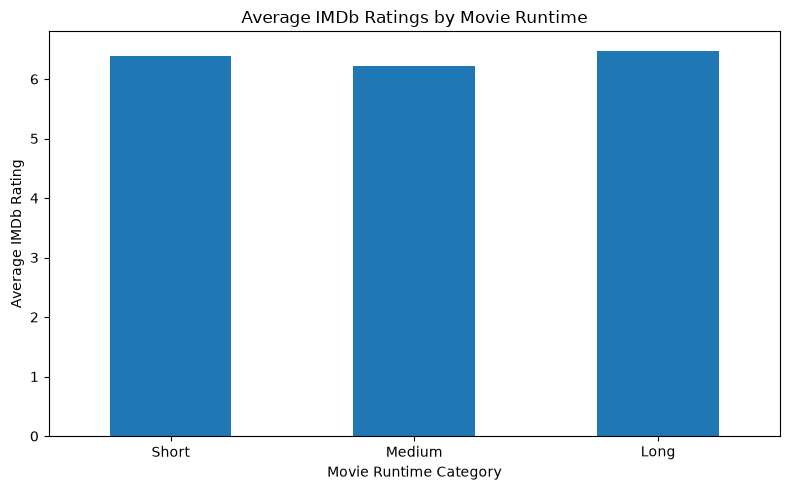

In [48]:
# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Create a bar chart using the average ratings
runtime_analysis['average_rating'].plot(
    kind='bar',
    figsize=(8, 5)
)

# Add a title and axis labels
plt.title('Average IMDb Ratings by Movie Runtime')
plt.xlabel('Movie Runtime Category')
plt.ylabel('Average IMDb Rating')

# Keep the category names horizontal
plt.xticks(rotation=0)

# Display the graph
plt.tight_layout()
plt.show()

In [49]:
# Round the average ratings to 2 decimal places
# Keep the number of movies as whole numbers

runtime_analysis['average_rating'] = runtime_analysis['average_rating'].round(2)

# Display the final comparison table
runtime_analysis

,average_rating,number_of_movies
runtime_category,,
Short,6.39,28099
Medium,6.23,31551
Long,6.48,6586


Findings and Interpretation

The analysis investigated the relationship between movie runtime and average IMDb ratings for movies released between 2010 and 2019.

Long movies had the highest average rating of 6.48, followed by short movies at 6.39. Medium-length movies had the lowest average rating of 6.23.

These findings suggest that movie runtime may be associated with audience ratings. However, the differences were relatively small, and the results do not establish that longer movies are necessarily better rated. Other factors, such as genre, production quality and audience preferences, may influence ratings.